# Budgeted cross-modal plausibility checks: a walkthrough

This notebook goes through the pipeline on the MIMIC-IV demo resampled to a trial
visit schedule, then loads the results. It needs the processed data and the
results tables (`make all`, or the steps up to `make explain`).

The question: at a fixed query budget, measured in queries per patient per visit,
does a cross-modal plausibility model catch more injected transcription errors
than EDC-style range rules? Every number shown is on held-out patients unless
said otherwise. The plan is in `docs/analysis_plan.md`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

sys.path.insert(0, str(Path.cwd().parent / "src"))
from bcp import cli, config as C, inject as I

pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 200)
data = cli.load_processed()
tables = C.TABLES_DIR
summary = json.loads((C.RESULTS_DIR / "summary.json").read_text())

## 1. The visit table

Day 0 is ICU admission. Visits D1 to D7 are daily, W2 to W4 weekly. A cell is one
recorded value of one field at one visit, or the date of a lab or vital signs form.

In [2]:
cells = data["cells"]
print(f"{cells.subject_id.nunique()} patients, {len(data['visits'])} patient-visits, {len(cells):,} cells")
display(cells.groupby(["visit", "modality"]).size().unstack(fill_value=0)
        .reindex([v[0] for v in C.VISITS]))

99 patients, 621 patient-visits, 11,007 cells


modality,date,lab,med,vital
visit,,,,
D1,189,1236,157,681
D2,150,1165,151,414
D3,125,1043,147,323
D4,107,892,130,253
D5,83,662,109,199
D6,66,607,85,126
D7,57,494,81,127
W2,56,365,25,125
W3,36,212,23,73


One patient's laboratory values over the schedule (the patient is shown by a
number, not by MIMIC identifier):

In [3]:
pid = cells.groupby("subject_id").visit.nunique().sort_values().index[-1]
one = cells[(cells.subject_id == pid) & (cells.modality == "lab")]
display(one.pivot_table(index="field", columns="visit", values="value", aggfunc="first")
        .reindex(columns=[v[0] for v in C.VISITS]).dropna(axis=1, how="all"))

visit,D1,D2,D3,D4,D5,D6,D7,W2,W3,W4
field,,,,,,,,,,
bicarbonate,15.0,17.0,16.0,16.0,17.0,19.0,15.0,20.0,21.0,26.0
bun,32.0,31.0,30.0,32.0,31.0,34.0,26.0,4.0,39.0,42.0
calcium,7.3,NaN,8.1,8.3,8.5,8.5,10.7,8.2,9.0,8.9
chloride,112.0,112.0,114.0,115.0,115.0,113.0,117.0,108.0,104.0,100.0
creatinine,1.8,1.8,1.9,2.2,2.4,2.5,2.1,0.6,3.0,3.5
glucose,207.0,166.0,176.0,140.0,161.0,278.0,109.0,91.0,92.0,94.0
hematocrit,27.8,25.3,28.8,26.2,24.2,24.0,20.4,23.7,22.7,23.5
hemoglobin,9.4,8.6,9.6,8.8,8.2,8.1,7.2,8.0,7.5,7.5
magnesium,1.8,2.1,1.9,2.1,1.9,1.9,2.6,1.9,2.5,2.3


## 2. The six transcription errors

Each mechanism works on the value as written. Shown on made-up values:

In [4]:
rng = np.random.default_rng(0)
rows = [
    ("digit transposition", "sodium 142", I.transpose_digits(142, 0, rng)),
    ("digit transposition", "potassium 4.6", I.transpose_digits(4.6, 1, rng)),
    ("unit error", "glucose 108 mg/dL", I.unit_error(108, C.VALUE_FIELDS["glucose"]["alt"])),
    ("unit error", "creatinine 1.0 mg/dL", I.unit_error(1.0, C.VALUE_FIELDS["creatinine"]["alt"])),
    ("unit error", "weight 80.0 kg", I.unit_error(80.0, C.VALUE_FIELDS["weight"]["alt"])),
    ("decimal slip", "hemoglobin 9.8", I.decimal_slip(9.8, 1, rng)),
    ("decimal slip", "heart rate 98", I.decimal_slip(98, 0, rng)),
]
display(pd.DataFrame(rows, columns=["error", "recorded", "written instead"]))
d = (pd.Timestamp("2150-03-12") - pd.Timestamp("1970-01-01")).days
typos = I.date_typos(d)
display(pd.DataFrame([(k, [str(pd.Timestamp("1970-01-01") + pd.Timedelta(days=x))[:10] for x in v]) for k, v in typos.items()],
                     columns=["wrong date for 2150-03-12", "options"]))

,error,recorded,written instead
0,digit transposition,sodium 142,124.0
1,digit transposition,potassium 4.6,6.4
2,unit error,glucose 108 mg/dL,6.0
3,unit error,creatinine 1.0 mg/dL,88.0
4,unit error,weight 80.0 kg,176.4
5,decimal slip,hemoglobin 9.8,98.0
6,decimal slip,heart rate 98,980.0


,wrong date for 2150-03-12,options
0,day_month_exchanged,[2150-12-03]
1,day_digits_exchanged,[2150-03-21]
2,month_off_by_one,"[2150-02-12, 2150-04-12]"
3,year_off_by_one,"[2149-03-12, 2151-03-12]"


Copied values and patient swaps work on the table: a value is replaced by the
same patient's previous visit, or exchanged with the same field and visit of
another patient in the same split. One replicate at 2%:

In [5]:
counts = json.loads((tables / "injection_primary.json").read_text())
display(pd.DataFrame({t: counts[0][t] for t in C.ERROR_TYPES}).T)
print("held-out cells:", counts[0]["n_test_cells"], " injected errors among them:", counts[0]["n_test_errors"])

,planned,injected
wrong_date,37,37
patient_swap,37,36
copy_previous,37,37
unit_error,37,37
decimal_slip,36,36
digit_transposition,36,36


held-out cells: 5422  injected errors among them: 103


## 3. What the detectors raise

Example queries from replicate 0 at the primary budget of 0.25 queries per patient
per visit. The ground truth column is not visible to the detectors.

In [6]:
ex = pd.read_parquet(C.CELLS_DIR / "example_queries.parquet")
for det in ("rules", "model_full", "delta"):
    d = ex[ex.detector == det]
    print(f"{det}: {len(d)} queries, {(d.error_type != 'none').mean():.0%} on injected errors")
pick = pd.concat([ex[(ex.detector == "model_full") & (ex.error_type == t)].head(1) for t in C.ERROR_TYPES + ["none"]])
display(pick[["detector", "rank", "error_type", "query"]])

rules: 75 queries, 69% on injected errors
model_full: 76 queries, 66% on injected errors
delta: 76 queries, 32% on injected errors


,detector,rank,error_type,query
161,model_full,11,wrong_date,The laboratory sample date 2118-03-22 for visit D7 does not fit the rest of the record: 366 days after the scheduled date. Please check against the source document.
199,model_full,49,patient_swap,"Diastolic BP 77 mmHg at visit D7 does not fit the rest of the record: diastolic BP 63 mmHg 3 days earlier, mean arterial pressure 62 mmHg and systolic BP 98 mmHg at the same visit. Please check ag..."
153,model_full,3,unit_error,"Hemoglobin 121.0 g/dL at visit D3 is outside the expected range 5.0 to 20.0 g/dL and does not fit the rest of the record: hemoglobin 11.8 g/dL 2 days earlier, hemoglobin 13.0 g/dL 1 day later. Ple..."
151,model_full,1,decimal_slip,"Chloride 970 mmol/L at visit D1 is outside the expected range 75 to 130 mmol/L and does not fit the rest of the record: chloride 97 mmol/L 1 day later, sodium 136 mmol/L and bicarbonate 29 mmol/L ..."
169,model_full,19,digit_transposition,"Heparin (SC) daily dose 51,000 units/day at visit D1 is outside the expected range 2,500 to 22,500 units/day and does not fit the rest of the record: heparin (SC) daily dose 15,000 units/day 1 day..."
186,model_full,36,none,"Calcium 2.7 mg/dL at visit D5 is outside the expected range 5.0 to 14.0 mg/dL and does not fit the rest of the record: calcium 8.3 mg/dL 1 day earlier, calcium 8.5 mg/dL 1 day later. Please check ..."


## 4. Errors caught at a fixed budget

Primary endpoint: errors caught per budgeted query at 0.25 queries per patient per
visit, model minus range rules, 95% patient bootstrap interval.

In [7]:
p = summary["primary"]
display(Markdown(f"**Model {p['model_yield']:.3f} vs range rules {p['rules_yield']:.3f} errors per query; "
                 f"difference {p['difference']:+.3f} (95% CI {p['difference_lo']:+.3f} to {p['difference_hi']:+.3f}): "
                 f"{p['verdict']}.**"))
b = pd.read_csv(tables / "budget_metrics.csv")
for metric in ("yield", "precision", "recall", "queries_raised"):
    t = b[b.metric == metric].pivot(index="detector", columns="budget", values="estimate")
    display(Markdown(f"`{metric}`"), t.round(3))

**Model 0.690 vs range rules 0.661 errors per query; difference +0.029 (95% CI -0.031 to +0.138): no clear difference.**

`yield`

budget,0.05,0.10,0.25,0.50,1.00
detector,,,,,
combined,0.753,0.787,0.667,0.424,0.235
delta,0.497,0.437,0.308,0.191,0.116
model_full,1.000,0.960,0.690,0.418,0.233
rules,0.743,0.787,0.661,0.349,0.175


`precision`

budget,0.05,0.10,0.25,0.50,1.00
detector,,,,,
combined,0.753,0.787,0.667,0.424,0.235
delta,0.497,0.437,0.308,0.191,0.116
model_full,1.000,0.960,0.690,0.418,0.233
rules,0.743,0.787,0.670,0.667,0.667


`recall`

budget,0.05,0.10,0.25,0.50,1.00
detector,,,,,
combined,0.108,0.232,0.482,0.614,0.682
delta,0.071,0.129,0.222,0.277,0.337
model_full,0.143,0.283,0.498,0.607,0.675
rules,0.106,0.232,0.478,0.507,0.507


`queries_raised`

budget,0.05,0.10,0.25,0.50,1.00
detector,,,,,
combined,15.0,31.0,76.0,153.00,306.00
delta,15.0,31.0,76.0,153.00,306.00
model_full,15.0,31.0,76.0,153.00,306.00
rules,15.0,31.0,75.0,80.05,80.05


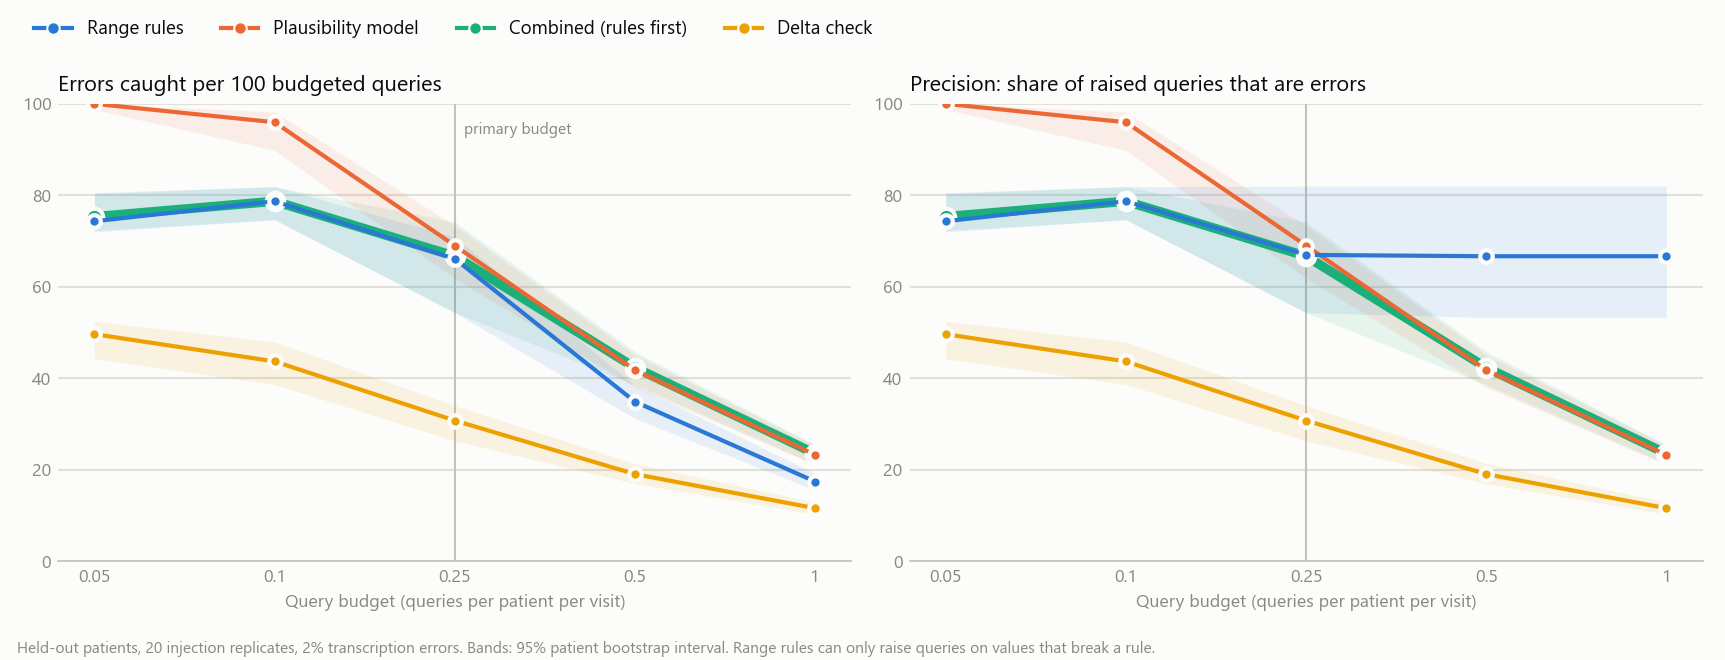

In [8]:
display(Image(str(C.FIGURES_DIR / "budget_comparison.png")))

Differences to range rules at every budget (descriptive, no multiplicity adjustment):

In [9]:
d = b[b.metric == "diff_vs_rules|yield"].copy()
d["interval"] = d.apply(lambda r: f"{r.estimate:+.3f} ({r.lo:+.3f}, {r.hi:+.3f})", axis=1)
display(d.pivot(index="detector", columns="budget", values="interval"))

budget,0.05,0.10,0.25,0.50,1.00
detector,,,,,
combined,"+0.010 (-0.028, +0.028)","+0.000 (-0.005, +0.006)","+0.006 (+0.000, +0.059)","+0.075 (+0.056, +0.094)","+0.061 (+0.054, +0.067)"
delta,"-0.247 (-0.337, -0.223)","-0.350 (-0.400, -0.295)","-0.353 (-0.411, -0.237)","-0.158 (-0.187, -0.129)","-0.058 (-0.069, -0.048)"
model_full,"+0.257 (+0.191, +0.279)","+0.173 (+0.108, +0.215)","+0.029 (-0.031, +0.138)","+0.069 (+0.044, +0.090)","+0.058 (+0.052, +0.066)"


## 5. Recall by error type and size

detector,combined,delta,model_full,rules
error type,,,,
copy_previous,0.00,0.01,0.00,0.00
decimal_slip,0.85,0.53,0.89,0.83
digit_transposition,0.39,0.29,0.49,0.39
patient_swap,0.00,0.05,0.06,0.00
unit_error,0.65,0.47,0.75,0.64
wrong_date,1.00,0.00,0.80,1.00


detector,combined,delta,model_full,rules
error size,,,,
0.5-2.0 sd,0.01,0.06,0.02,0.01
< 0.5 sd,0.00,0.01,0.01,0.00
> 2.0 sd,0.66,0.45,0.76,0.65
date > 7 days,1.00,0.00,0.80,1.00


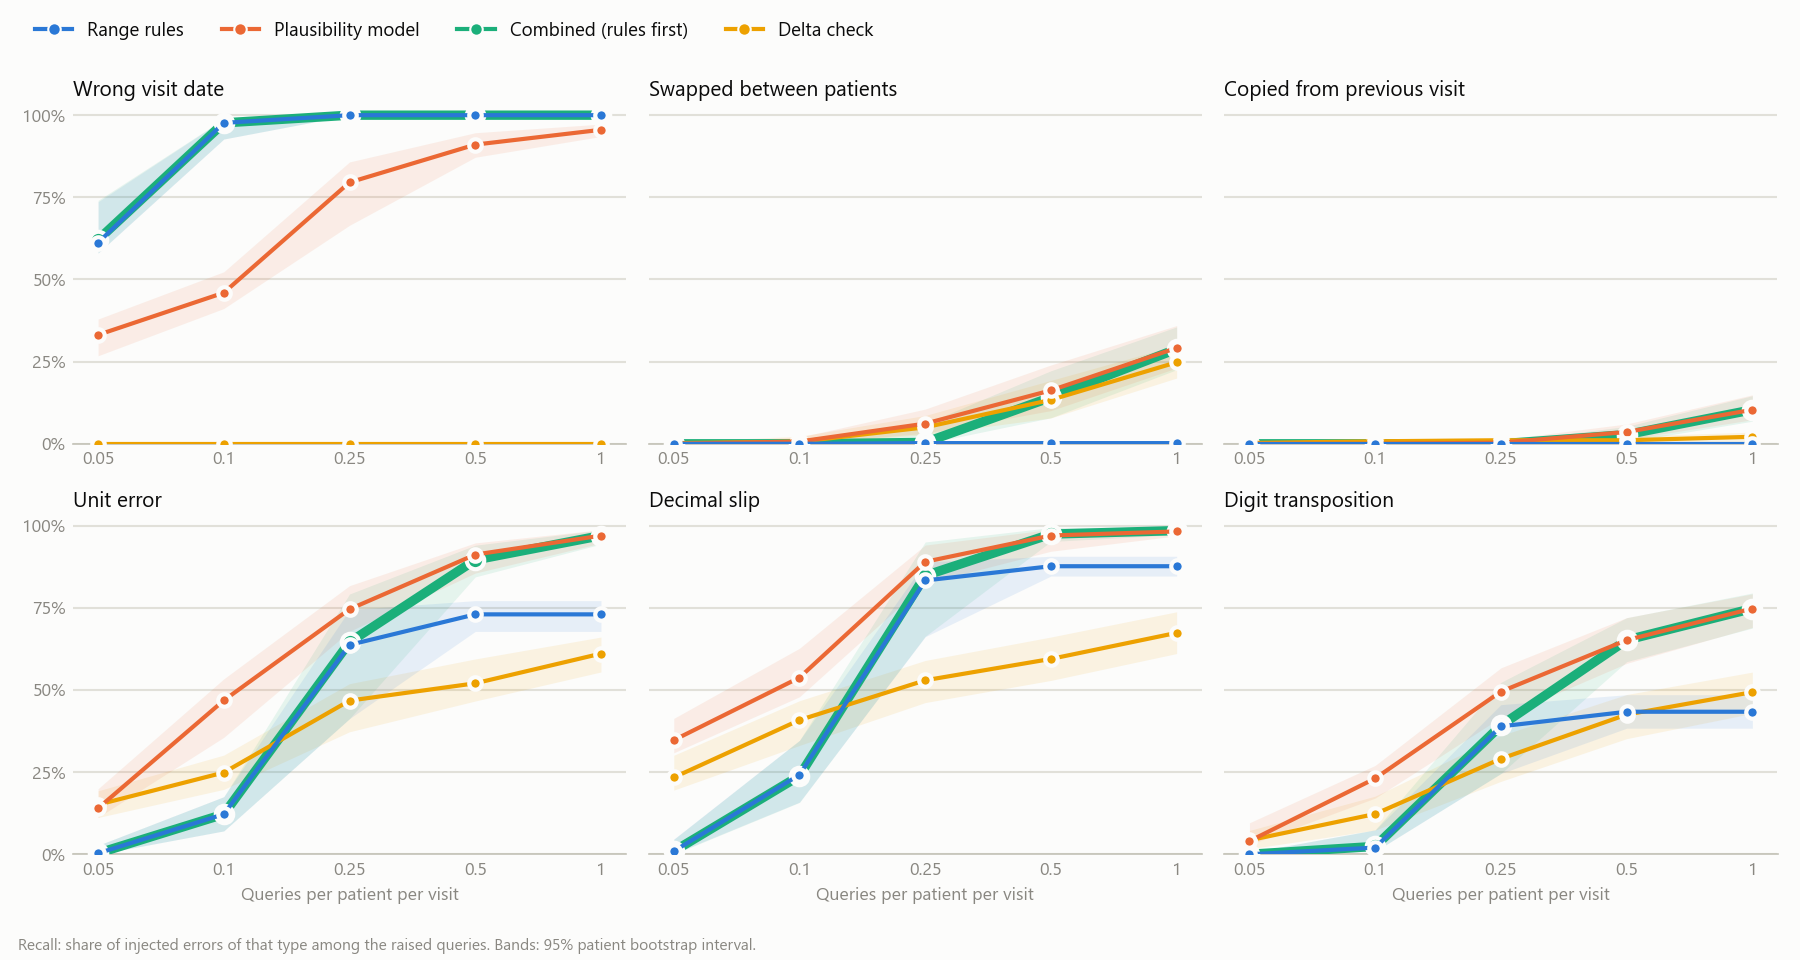

In [10]:
t = b[(b.budget == C.PRIMARY_BUDGET) & b.metric.str.startswith("recall|type:")].copy()
t["error type"] = t.metric.str.replace("recall|type:", "", regex=False)
display(t.pivot(index="error type", columns="detector", values="estimate").round(2))
s = b[(b.budget == C.PRIMARY_BUDGET) & b.metric.str.startswith("recall|size:")].copy()
s["error size"] = s.metric.str.replace("recall|size:", "", regex=False)
display(s.pivot(index="error size", columns="detector", values="estimate").round(2))
display(Image(str(C.FIGURES_DIR / "recall_by_type.png")))

## 6. Which context matters (ablation)

,detector,estimate,lo,hi,estimate vs full,lo vs full,hi vs full
0,model_full,0.682,0.603,0.740,NaN,NaN,NaN
1,model_cross_modal_only,0.636,0.563,0.697,-0.046,-0.076,-0.009
2,model_own_history_only,0.676,0.598,0.737,-0.005,-0.034,0.025
3,model_no_labs,0.693,0.614,0.753,0.012,-0.015,0.038
4,model_no_vitals,0.684,0.601,0.748,0.003,-0.017,0.023
5,model_no_meds,0.682,0.605,0.744,0.000,-0.013,0.020
6,model_no_dates,0.679,0.604,0.742,-0.003,-0.005,0.007
7,model_no_baseline,0.670,0.593,0.738,-0.012,-0.024,0.014


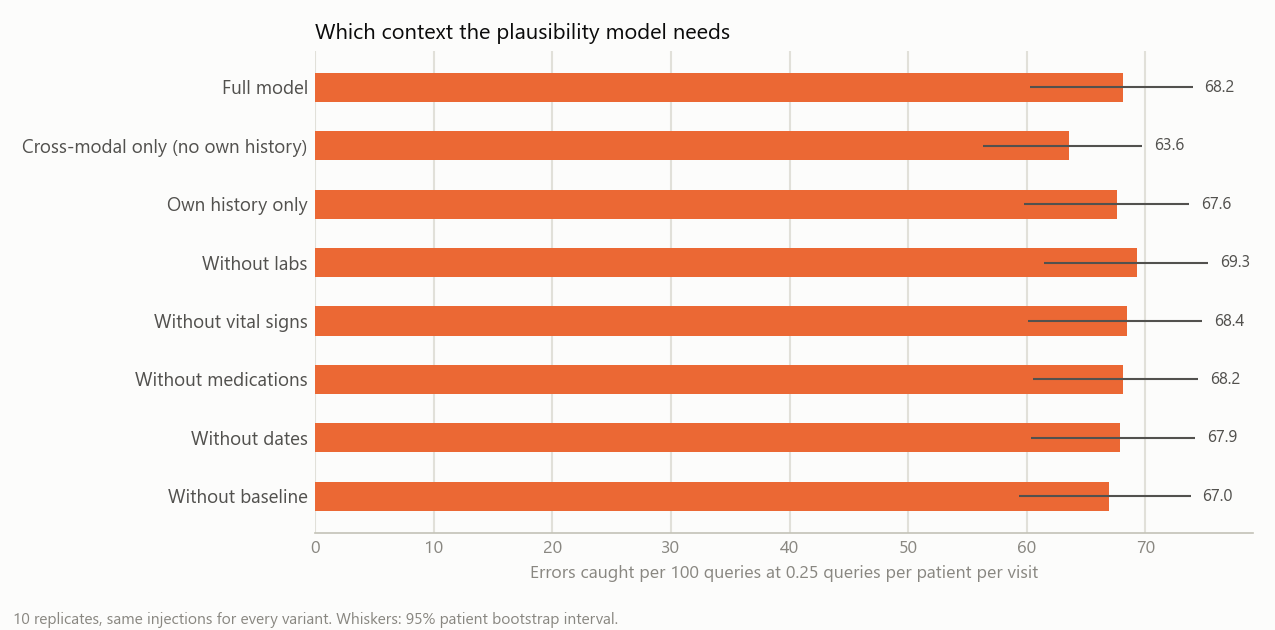

In [11]:
a = pd.read_csv(tables / "ablation.csv")
y = a[(a.budget == C.PRIMARY_BUDGET) & (a.metric == "yield")][["detector", "estimate", "lo", "hi"]]
dd = a[(a.budget == C.PRIMARY_BUDGET) & (a.metric == "diff_vs_full|yield")][["detector", "estimate", "lo", "hi"]]
display(y.merge(dd, on="detector", how="left", suffixes=("", " vs full")).round(3))
display(Image(str(C.FIGURES_DIR / "ablation.png")))

## 7. False-query control with conformal p-values

Conformal p-values from clean visits of training patients, Benjamini-Hochberg
within each of five pseudo-sites. Intervals are the spread over the 20
replicates (deviation 1 in the plan). **The guarantee assumes that the calibration
data are clean; here they are only free of injected errors, and real
calibration data never are fully clean.**

metric             errors_caught  false_query_rate  mean_site_false_query_rate  queries_per_patient_visit  queries_raised  recall
detector   target                                                                                                                
combined   0.1             26.30             0.273                       0.144                      0.138           42.30   0.243
           0.2             49.95             0.394                       0.291                      0.267           81.85   0.472
delta      0.1              0.25             0.050                       0.010                      0.002            0.50   0.002
           0.2              1.00             0.128                       0.038                      0.006            1.95   0.009
model_full 0.1             24.85             0.057                       0.035                      0.087           26.70   0.234
           0.2             38.80             0.171                       0.126                      0.157           47.90   0.368
rules      0.1             25.20             0.237                       0.134                      0.128           39.20   0.232
           0.2             46.20             0.357                       0.271                      0.233           71.25   0.437

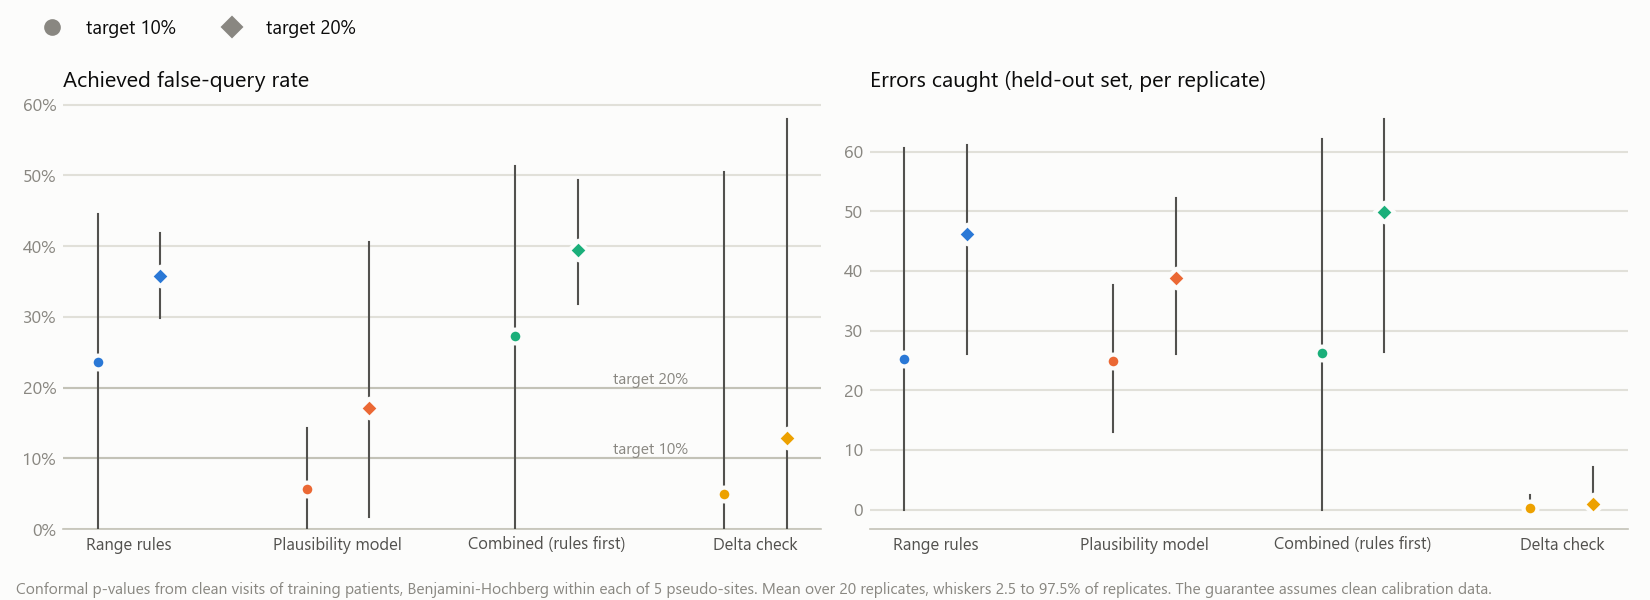

In [12]:
c = pd.read_csv(tables / "conformal.csv")
display(c.pivot_table(index=["detector", "target"], columns="metric", values="estimate").round(3))
display(Image(str(C.FIGURES_DIR / "conformal.png")))

## 8. Index of individuality and swap detectability

Spearman rho = -0.80, one-sided permutation p = 0.1643, 4 fields. Hypothesis holds: **False**. Fields changed by cross-modal context: chloride, hematocrit. Exploratory, not pre-registered, all 22 fields: rho = -0.55, p = 0.0054.

,field,index_of_individuality,auroc_own_history_only,auroc_full,gain_over_own_history,above_line,changed_by_cross_modal_context
11,hematocrit,0.427,0.648,0.827,0.178,0.165,True
2,chloride,0.598,0.682,0.778,0.096,0.081,True
3,bicarbonate,0.624,0.756,0.644,-0.112,-0.058,False
6,glucose,0.755,0.705,0.697,-0.008,-0.032,False


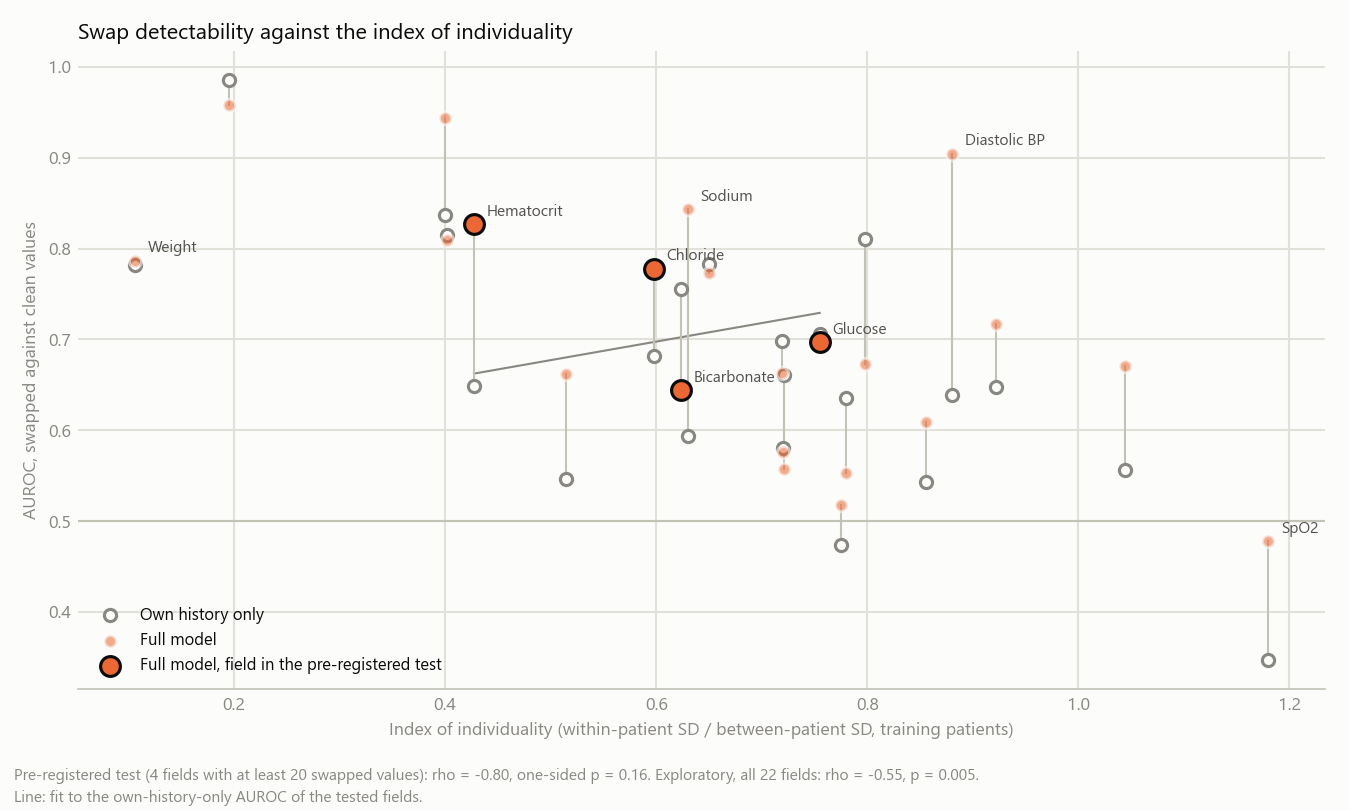

In [13]:
ii = summary["individuality"]
display(Markdown(f"Spearman rho = {ii['spearman_rho']:.2f}, one-sided permutation p = {ii['p_one_sided']:.4f}, "
                 f"{ii['n_fields']} fields. Hypothesis holds: **{ii['hypothesis_holds']}**. "
                 f"Fields changed by cross-modal context: {', '.join(ii['changed_by_cross_modal_context']) or 'none'}. "
                 f"Exploratory, not pre-registered, all {ii['exploratory_all_fields']['n_fields']} fields: "
                 f"rho = {ii['exploratory_all_fields']['spearman_rho']:.2f}, p = {ii['exploratory_all_fields']['p_one_sided']:.4f}."))
t = pd.read_csv(tables / "individuality.csv")
display(t[t.in_test][["field", "index_of_individuality", "auroc_own_history_only", "auroc_full",
                      "gain_over_own_history", "above_line", "changed_by_cross_modal_context"]]
        .sort_values("index_of_individuality").round(3))
display(Image(str(C.FIGURES_DIR / "individuality.png")))

## 9. Sensitivity to the error rate

In [14]:
rows = []
for rate in C.SENSITIVITY_RATES:
    h = summary[f"sensitivity_{rate}"]
    rows.append(dict(rate=rate, model=h["model_yield"], rules=h["rules_yield"], difference=h["difference"],
                     lo=h["difference_lo"], hi=h["difference_hi"], verdict=h["verdict"]))
p = summary["primary"]
rows.insert(1, dict(rate=C.ERROR_RATE, model=p["model_yield"], rules=p["rules_yield"], difference=p["difference"],
                    lo=p["difference_lo"], hi=p["difference_hi"], verdict=p["verdict"]))
display(pd.DataFrame(rows).round(3))

,rate,model,rules,difference,lo,hi,verdict
0,0.005,0.225,0.196,0.029,0.011,0.043,better
1,0.020,0.690,0.661,0.029,-0.031,0.138,no clear difference
2,0.050,0.976,0.816,0.161,0.110,0.199,better
